# Clustering Track — Credit Card Customer Segmentation

### 23CSE301 Machine Learning Capstone
**Dataset:** Credit Card Dataset for Clustering (`credit_card.csv`)
**Goal:** identify groups of customers with similar credit-card usage patterns using unsupervised learning.

This notebook includes data audit, EDA, cleaning, scaling, K-Means, Elbow analysis, Agglomerative Hierarchical Clustering, a dendrogram, the three required metrics, PCA and t-SNE. All plots and tables are displayed inline; no output folder is required.

Run cells from top to bottom. Cluster count `4` is an initial setting and should be reconsidered after inspecting the Elbow curve and evaluation metrics.

#### Step 1 — Import libraries and set global options

**What this cell does:** Loads every library the notebook needs: pandas/NumPy for data, matplotlib/seaborn for plots, scikit-learn for imputation, scaling, K-Means, Agglomerative clustering, the three evaluation metrics, PCA and t-SNE, and SciPy for the dendrogram. It also hides warnings and fixes `RANDOM_STATE = 42` so every run gives the same results.

**What you will see:** Nothing is printed — this cell only prepares the environment.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

#### Step 2 — Load the dataset

**What this cell does:** Reads `credit_card.csv` into a DataFrame called `df`, then prints its shape and shows the first 5 rows.

**Why it matters:** A first look confirms the file loaded correctly and shows what each column looks like.

**What you will see:** The dataset shape (rows, columns) and a 5-row preview table.

In [2]:
df = pd.read_csv("credit_card.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


#### Step 3 — Data audit: types, missing values, duplicates, statistics

**What this cell does:** Checks the quality of the raw data: the data type of each column, how many values are missing per column, how many duplicate rows exist, and descriptive statistics (mean, std, min, quartiles, max) for every numeric column.

**Why it matters:** Clustering is sensitive to bad data. Missing values, wrong data types and extreme ranges must be found before any model is trained.

**What you will see:** Four outputs in order: a data-types table, a missing-values table, the duplicate-row count and a statistics table.

In [3]:
print("Column data types:")
display(df.dtypes.to_frame("Data Type"))

print("Missing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Count")
)

print("Duplicate rows:", df.duplicated().sum())

print("Descriptive statistics:")
display(df.describe().T)

Column data types:


,Data Type
CUST_ID,str
BALANCE,float64
BALANCE_FREQUENCY,float64
PURCHASES,float64
ONEOFF_PURCHASES,float64
INSTALLMENTS_PURCHASES,float64
CASH_ADVANCE,float64
PURCHASES_FREQUENCY,float64
ONEOFF_PURCHASES_FREQUENCY,float64
PURCHASES_INSTALLMENTS_FREQUENCY,float64


Missing values:


,Missing Count
MINIMUM_PAYMENTS,313
CREDIT_LIMIT,1
BALANCE,0
CUST_ID,0
BALANCE_FREQUENCY,0
PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0


Duplicate rows: 0
Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


#### Step 4 — EDA: distribution of every feature

**What this cell does:** Drops the identifier column `CUST_ID`, keeps only the numeric columns (`eda_df`) and draws a histogram for each one.

**Why it matters:** Histograms show the shape of each feature. Long right tails mean the feature is skewed, which is the reason a log transform is applied later.

**What you will see:** One grid of histograms, one small chart per feature.

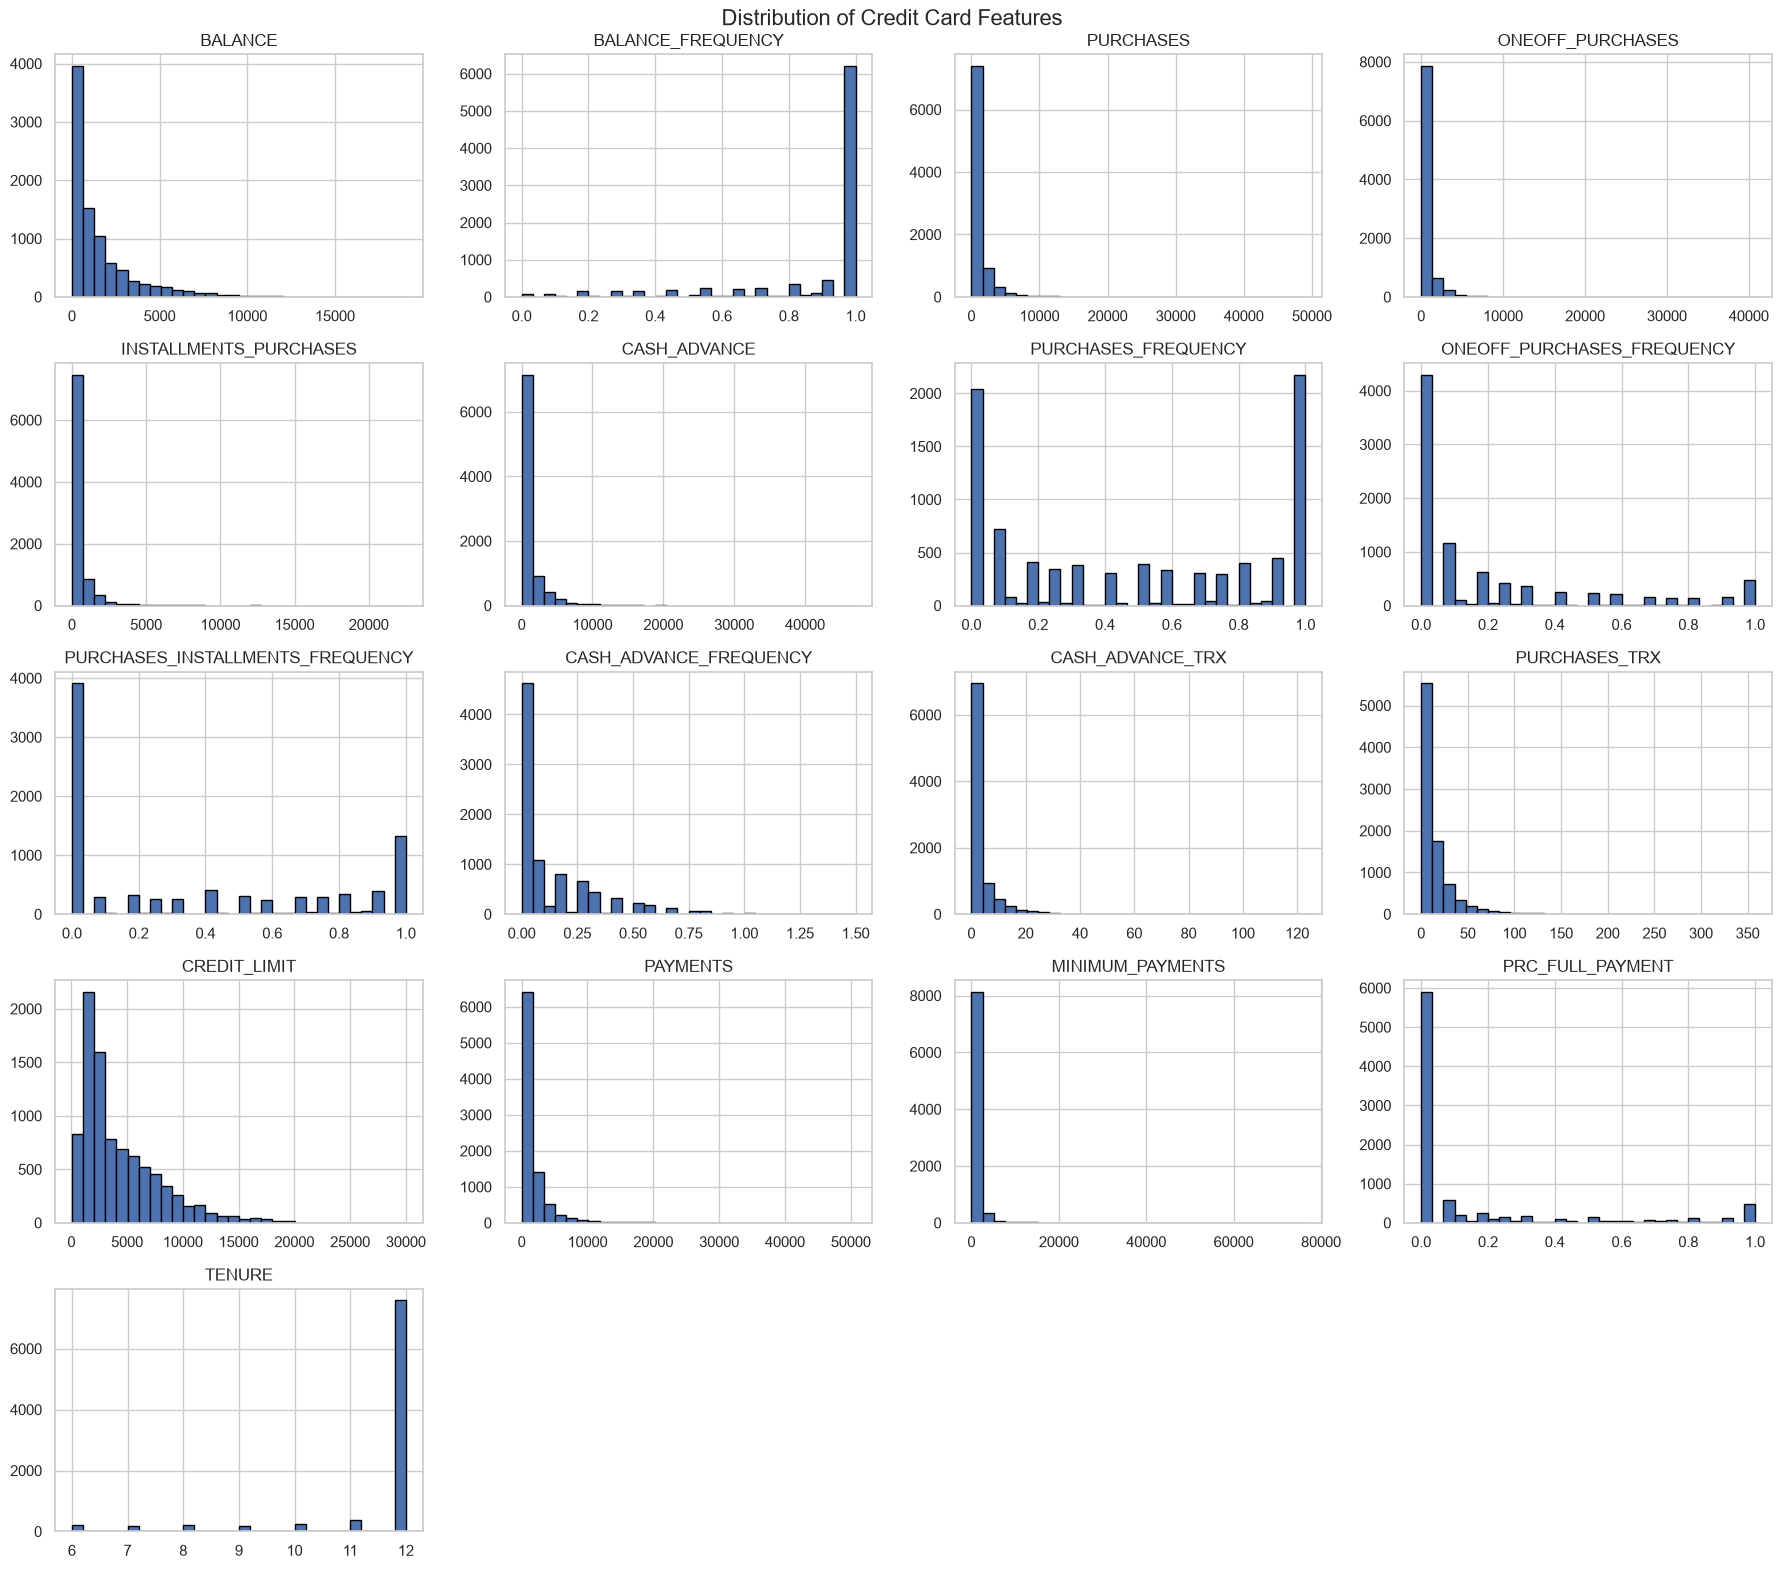

In [4]:
eda_df = df.drop(columns=["CUST_ID"], errors="ignore")
eda_df = eda_df.select_dtypes(include="number")

eda_df.hist(
    figsize=(18, 16),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Credit Card Features", fontsize=16)
plt.tight_layout()
plt.show()

#### Step 5 — EDA: correlation heatmap

**What this cell does:** Computes the correlation between every pair of numeric features and shows it as a colour-coded heatmap with the numbers written in each square.

**Why it matters:** Strongly correlated features carry overlapping information, so they influence the distance calculation in the clustering more than their count suggests.

**What you will see:** A heatmap: red = positive correlation, blue = negative, white = none.

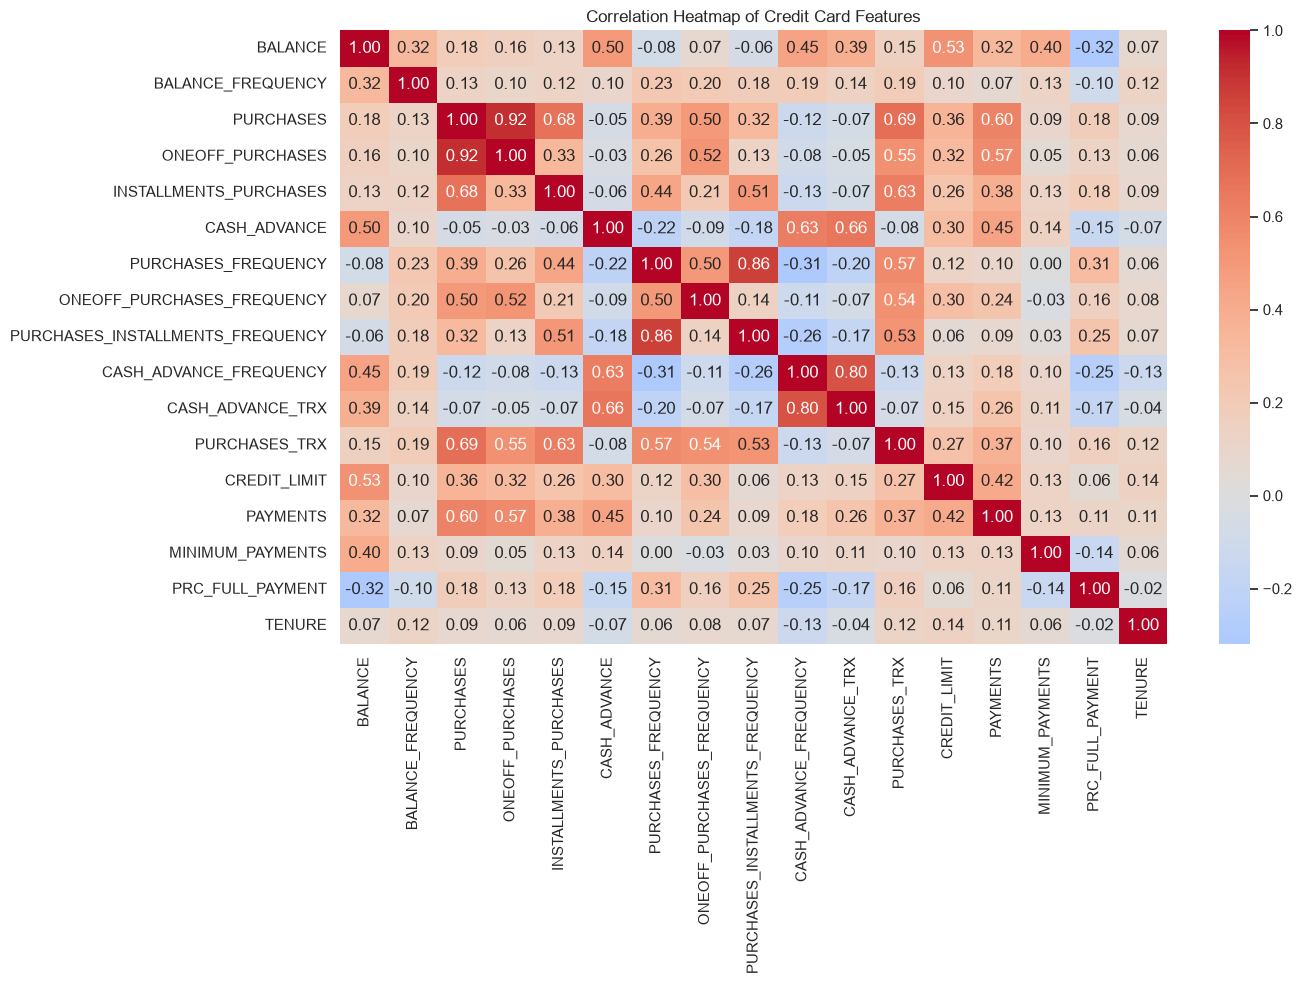

In [5]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    eda_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Credit Card Features")
plt.tight_layout()
plt.show()

#### Step 6 — EDA: outlier inspection with box plots

**What this cell does:** Loops over every numeric feature and draws one box plot per feature.

**Why it matters:** Points far outside the box are outliers. Credit-card data has many of them (a few customers spend or borrow far more than others), which affects K-Means.

**What you will see:** One box plot per feature (17 small charts, one under the other).

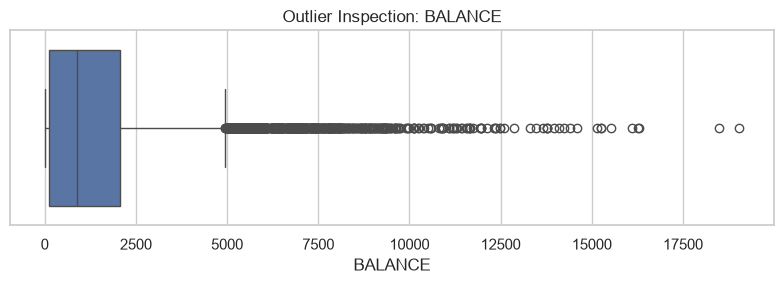

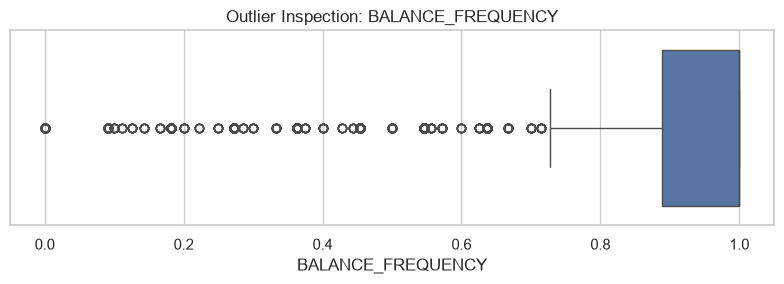

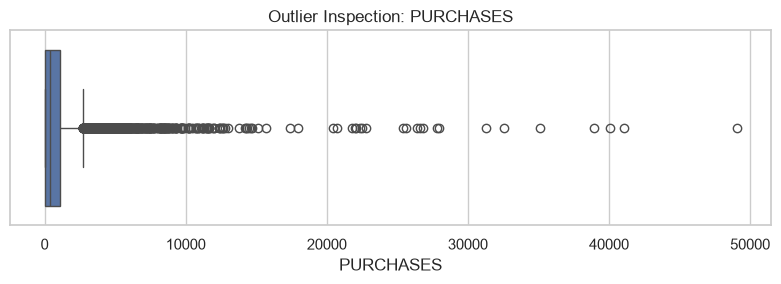

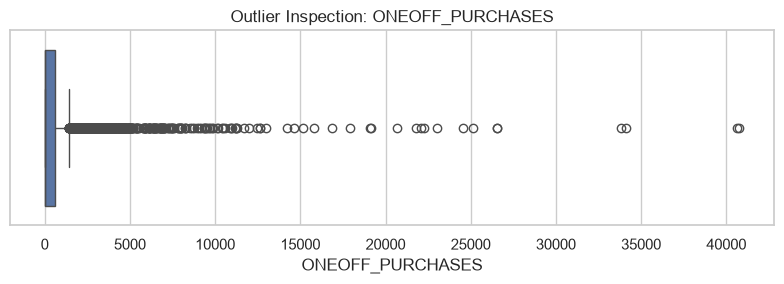

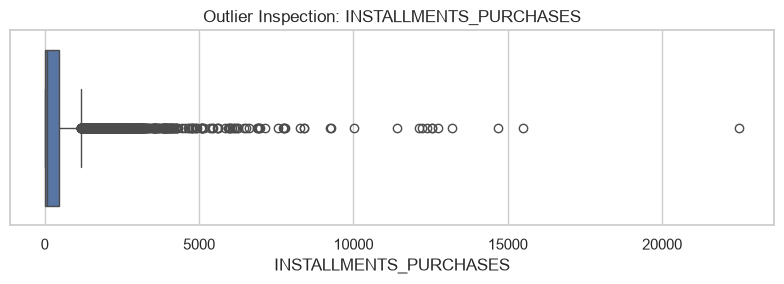

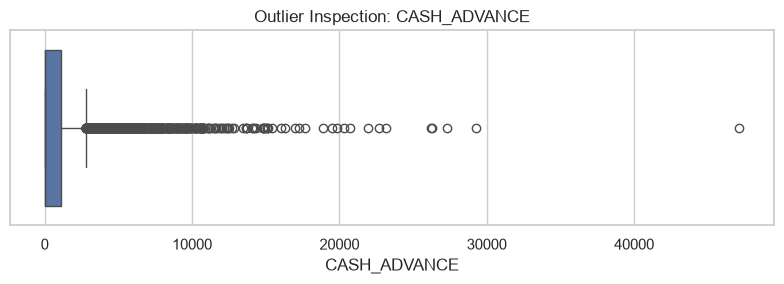

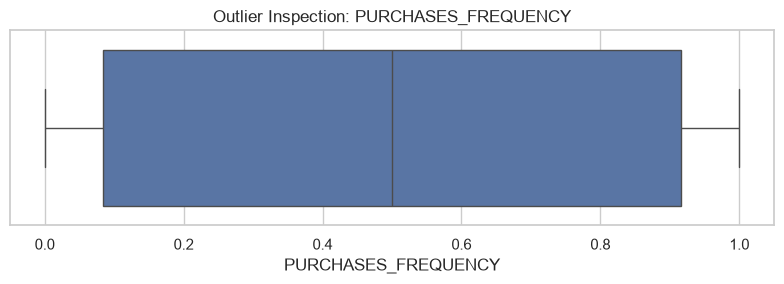

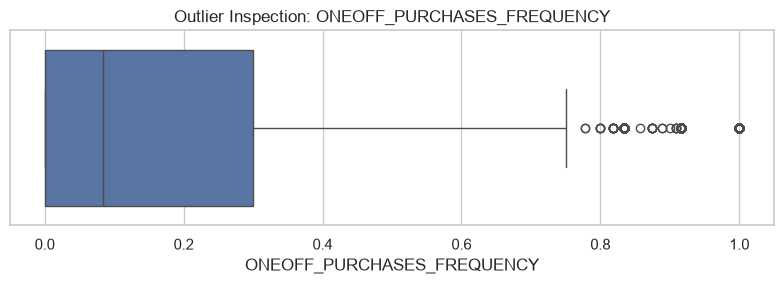

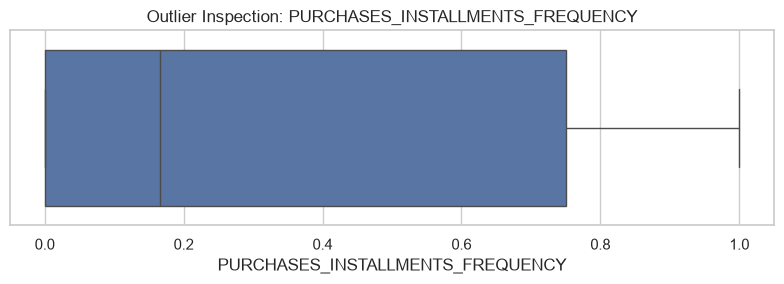

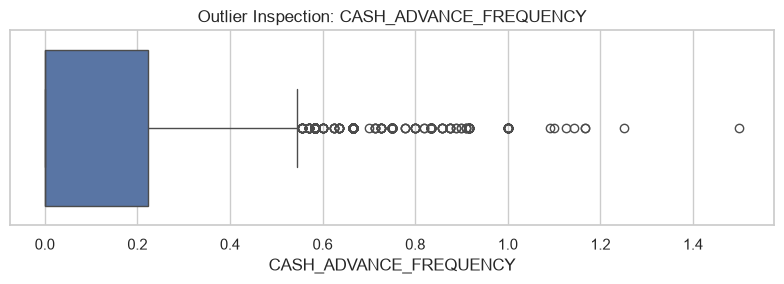

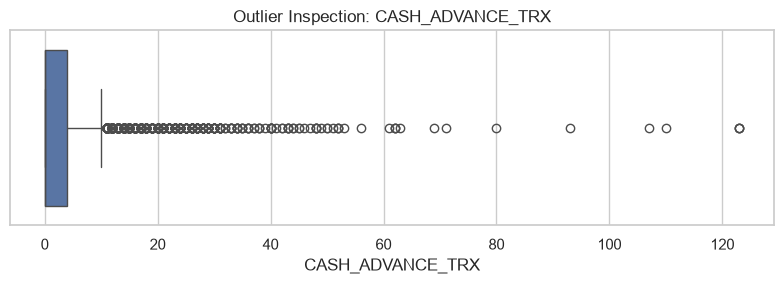

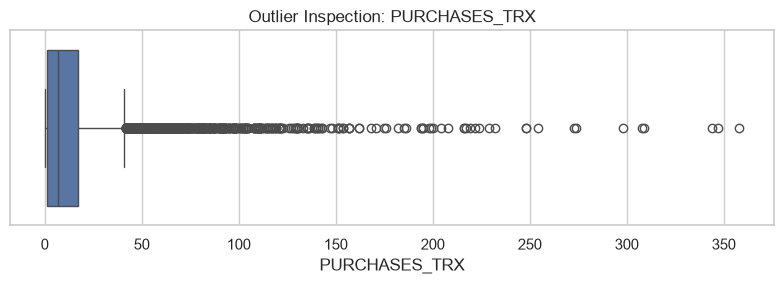

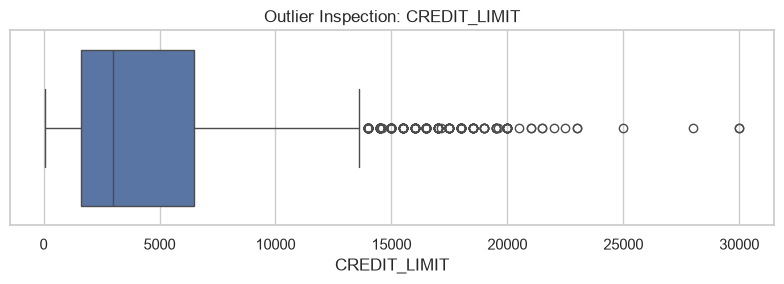

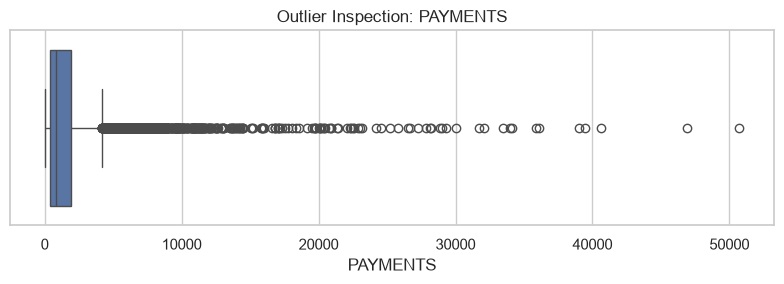

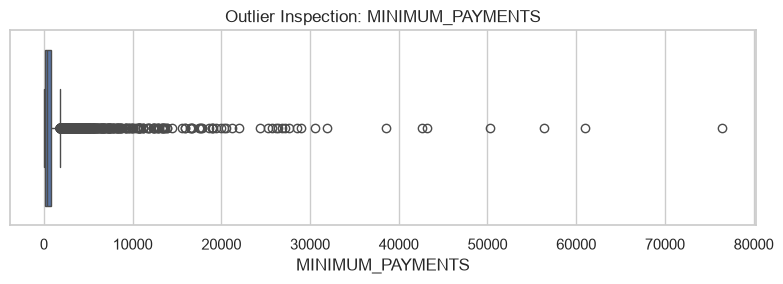

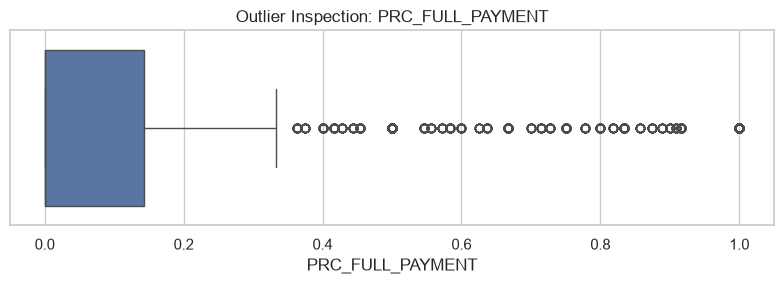

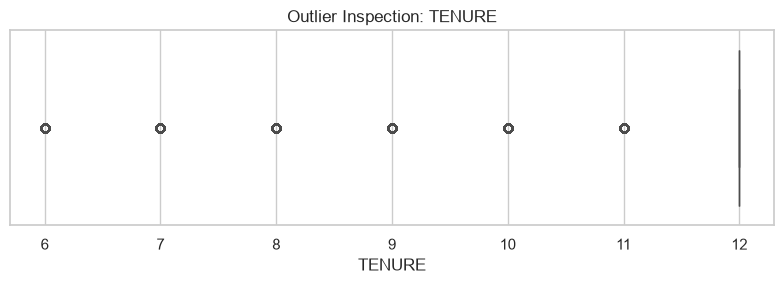

In [6]:
for col in eda_df.columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=eda_df[col])
    plt.title(f"Outlier Inspection: {col}")
    plt.tight_layout()
    plt.show()

#### Step 7 — Build the feature matrix `X_raw`

**What this cell does:** Removes `CUST_ID` (an identifier, not behaviour), converts every column to numeric, turns infinite values into missing values and drops any column that has no usable values. It then prints the remaining feature names and the number of missing values.

**Why it matters:** Only clean numeric behavioural features should reach the clustering algorithms.

**What you will see:** The list of remaining features and the count of missing values still to be filled.

In [7]:
# Remove customer identifier; it is not a behavioural feature.
X_raw = df.drop(columns=["CUST_ID"], errors="ignore").copy()

# Convert all features to numeric where possible.
X_raw = X_raw.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with missing values.
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)

# Remove columns with no usable observations.
X_raw = X_raw.dropna(axis=1, how="all")

print("Remaining features:", X_raw.columns.tolist())
print("Missing values before imputation:", X_raw.isna().sum().sum())

Remaining features: ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']
Missing values before imputation: 314


#### Step 8 — Fill missing values and reduce skew

**What this cell does:** Fills missing values with each column's median (`SimpleImputer`), then applies `log1p` to every non-negative feature whose skewness is above 1. The result is stored in `X_clean`.

**Why it matters:** The median is not distorted by outliers. The log transform compresses very long right tails so a few huge values do not dominate the clusters.

**What you will see:** The names of the log-transformed features and a missing-value count that should now be 0.

In [8]:
imputer = SimpleImputer(strategy="median")

X_clean = pd.DataFrame(
    imputer.fit_transform(X_raw),
    columns=X_raw.columns,
    index=X_raw.index
)

# Apply log1p only to non-negative features with strong right skew.
skewed_features = [
    col for col in X_clean.columns
    if (X_clean[col] >= 0).all() and X_clean[col].skew() > 1
]

for col in skewed_features:
    X_clean[col] = np.log1p(X_clean[col])

print("Log-transformed features:", skewed_features)
print("Missing values after imputation:", X_clean.isna().sum().sum())

Log-transformed features: ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'ONEOFF_PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT']
Missing values after imputation: 0


#### Step 9 — Scale the features (standardisation)

**What this cell does:** Applies `StandardScaler` so every feature has mean 0 and standard deviation 1, and checks with `assert` that no missing or infinite value remains. The scaled data is stored in `X_scaled`.

**Why it matters:** K-Means and hierarchical clustering are distance-based. Without scaling, a feature measured in thousands (for example `BALANCE`) would outweigh one measured between 0 and 1.

**What you will see:** The scaled shape and the first 5 rows of the scaled data.

In [9]:
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_clean),
    columns=X_clean.columns,
    index=X_clean.index
)

assert X_scaled.isna().sum().sum() == 0
assert np.isfinite(X_scaled.to_numpy()).all()

print("Scaled dataset shape:", X_scaled.shape)
display(X_scaled.head())

Scaled dataset shape: (8950, 17)


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-1.205218,-0.249434,-0.113532,-0.987090,0.394480,-0.930733,-0.806490,-0.732480,-0.707313,-0.724360,-0.810069,-0.579510,-1.447163,-0.824484,-0.829841,-0.556368,0.36068
1,0.948918,0.134325,-1.679855,-0.987090,-1.087454,1.528788,-1.221758,-0.732480,-0.916995,0.699592,0.784603,-1.379210,0.926060,1.065033,0.908184,0.391958,0.36068
2,0.824993,0.518084,0.600727,1.062022,-1.087454,-0.930733,1.269843,2.466762,-0.916995,-0.724360,-0.810069,0.487865,1.010229,-0.119300,0.450407,-0.556368,0.36068
3,0.624653,-1.016953,0.827499,1.265778,-1.087454,0.564372,-1.014125,-0.363042,-0.916995,-0.213583,-0.123281,-0.874655,1.010229,-4.161996,-0.144271,-0.556368,0.36068
4,0.271260,0.518084,-0.708481,-0.114307,-1.087454,-0.930733,-1.014125,-0.363042,-0.916995,-0.724360,-0.810069,-0.874655,-1.224909,-0.064979,-0.351833,-0.556368,0.36068


#### Step 10 — K-Means (Model 1) — Elbow analysis to choose k

**What this cell does:** Trains K-Means for every cluster count from k = 2 to 10 and records the inertia (total squared distance of the points to their cluster centre). It then plots inertia against k.

**Why it matters:** Inertia always falls as k grows. The 'elbow' — the point where the curve stops dropping steeply — suggests a sensible number of clusters.

**What you will see:** A line chart: Number of Clusters on the x-axis, Inertia on the y-axis.

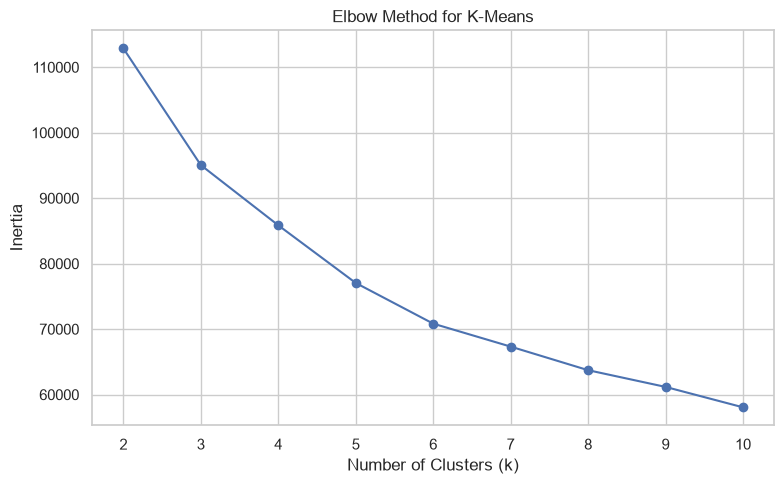

In [10]:
max_k = min(10, len(X_scaled) - 1)

if max_k < 2:
    raise ValueError("Not enough observations for clustering.")

k_values = range(2, max_k + 1)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

#### Step 11 — K-Means (Model 1) — final model

**What this cell does:** Fits K-Means with `BEST_K = 4` clusters (an initial setting that you should confirm from the Elbow curve and the metrics), assigns every customer a cluster label in `kmeans_labels` and counts the customers in each cluster.

**Why it matters:** These labels are the K-Means result used for the metrics, the PCA plot and the t-SNE plot later on.

**What you will see:** A table with the number of customers per cluster.

In [11]:
BEST_K = 4

kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means cluster counts:")
display(
    pd.Series(kmeans_labels, name="Cluster")
      .value_counts()
      .sort_index()
      .to_frame("Customers")
)

K-Means cluster counts:


,Customers
Cluster,
0,1923
1,3105
2,2393
3,1529


#### Step 12 — Hierarchical clustering (Model 2) — dendrogram

**What this cell does:** Takes a random sample of 1,000 customers (`rng`), builds a Ward linkage matrix and draws a dendrogram truncated to the last 30 merges.

**Why it matters:** A dendrogram shows how clusters merge step by step. Long vertical lines mean very different groups were merged, which hints at a natural number of clusters. A sample is used because a dendrogram of all customers is too slow and unreadable.

**What you will see:** A tree diagram: Ward Linkage Distance on the y-axis.

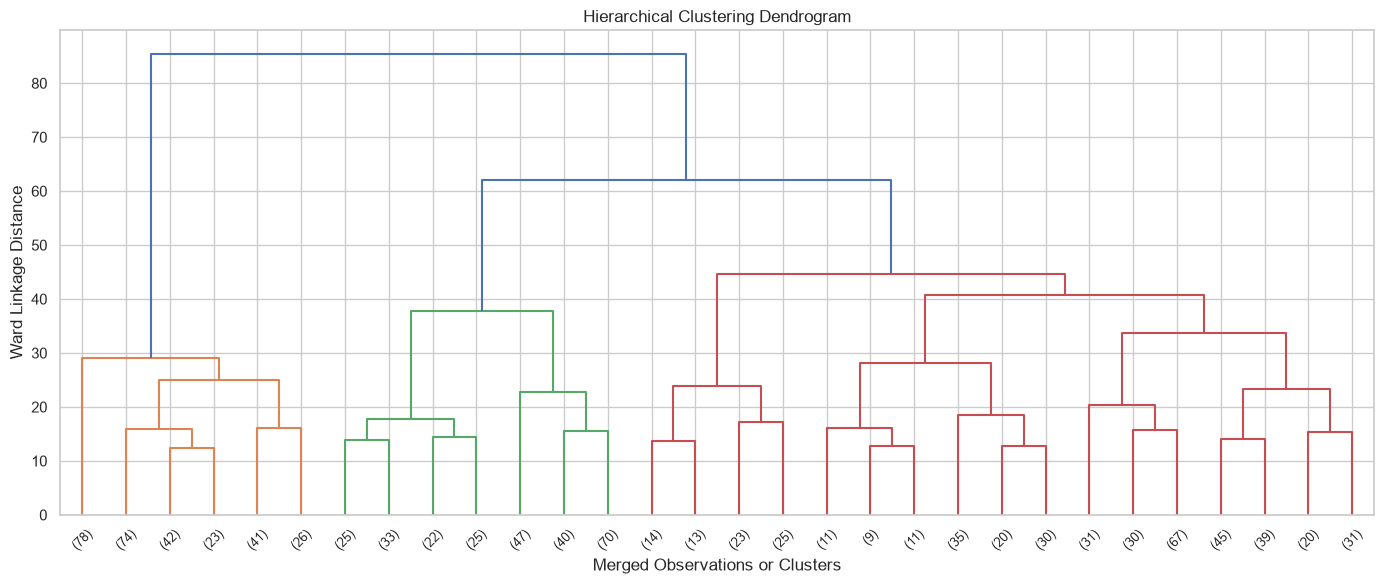

In [12]:
rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(1000, len(X_scaled))
sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_scaled.iloc[sample_indices]

linkage_matrix = linkage(
    X_sample.to_numpy(),
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=9
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Merged Observations or Clusters")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

#### Step 13 — Hierarchical clustering (Model 2) — final model

**What this cell does:** Fits `AgglomerativeClustering` with Ward linkage and the same `BEST_K = 4` on all scaled customers, stores the labels in `hierarchical_labels` and counts the customers per cluster.

**Why it matters:** Using the same number of clusters as K-Means makes the two algorithms directly comparable.

**What you will see:** A table with the number of customers per cluster.

In [13]:
hierarchical = AgglomerativeClustering(
    n_clusters=BEST_K,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical cluster counts:")
display(
    pd.Series(hierarchical_labels, name="Cluster")
      .value_counts()
      .sort_index()
      .to_frame("Customers")
)

Hierarchical cluster counts:


,Customers
Cluster,
0,2701
1,2245
2,1984
3,2020


#### Step 14 — Evaluate both models with three metrics

**What this cell does:** Defines `evaluate_model()` and computes the Silhouette Score, Davies-Bouldin Index and Calinski-Harabasz Index for K-Means and for Agglomerative clustering, then shows them side by side.

**Why it matters:** Clustering has no correct answer to compare against, so these internal metrics judge how compact and well separated the clusters are. Higher is better for Silhouette and Calinski-Harabasz; lower is better for Davies-Bouldin.

**What you will see:** A 2-row results table, one row per algorithm.

In [14]:
def evaluate_model(X, labels, model_name):
    n_clusters = len(np.unique(labels))

    if not 2 <= n_clusters < len(labels):
        raise ValueError("Invalid number of clusters for evaluation.")

    return {
        "Algorithm": model_name,
        "Number of Clusters": n_clusters,
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X, labels)
    }


results = pd.DataFrame([
    evaluate_model(X_scaled, kmeans_labels, "K-Means"),
    evaluate_model(
        X_scaled,
        hierarchical_labels,
        "Agglomerative Hierarchical"
    )
])

display(results.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,4,0.2150,1.6559,2302.5672
1,Agglomerative Hierarchical,4,0.1784,1.8456,1916.3725


#### Step 15 — Reduce to 2 dimensions with PCA

**What this cell does:** Projects the scaled data onto its first 2 principal components (`X_pca`) and prints how much of the total variance these 2 components keep.

**Why it matters:** People can only see 2 or 3 dimensions. PCA gives a flat picture of the clusters; the printed percentage tells you how much information that picture keeps.

**What you will see:** One line with the variance explained, in percent.

In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Variance explained by two components: 56.27 %


#### Step 16 — Helper function for 2D cluster plots

**What this cell does:** Defines `plot_clusters_2d()`, a reusable function that draws a scatter plot of 2D points coloured by cluster label and adds a legend. It is used for both PCA plots and the t-SNE plot.

**Why it matters:** Writing the plot code once avoids repeating it and keeps all cluster plots in the same style.

**What you will see:** Nothing is printed — the function is only defined here.

In [16]:
def plot_clusters_2d(components, labels, title):
    plt.figure(figsize=(9, 6))

    scatter = plt.scatter(
        components[:, 0],
        components[:, 1],
        c=labels,
        cmap="tab10",
        s=12,
        alpha=0.65
    )

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title(title)
    plt.legend(
        *scatter.legend_elements(),
        title="Cluster",
        loc="best"
    )
    plt.tight_layout()
    plt.show()

#### Step 17 — K-Means (Model 1) — PCA visualisation

**What this cell does:** Uses the helper to plot the PCA projection with every point coloured by its K-Means cluster.

**Why it matters:** Shows visually whether the K-Means clusters are separated or overlapping in the 2D view.

**What you will see:** One scatter plot titled 'K-Means Clusters — PCA'.

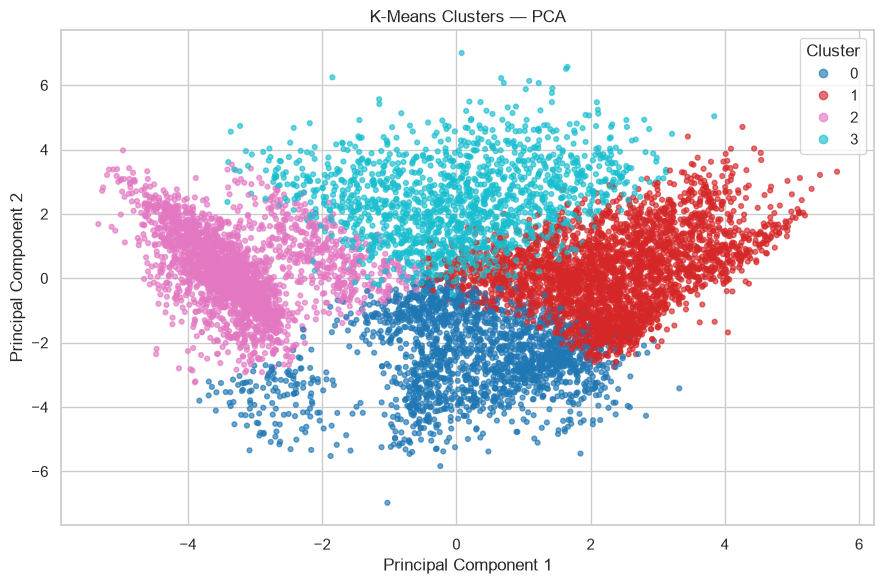

In [17]:
plot_clusters_2d(X_pca, kmeans_labels, "K-Means Clusters — PCA")

#### Step 18 — Hierarchical clustering (Model 2) — PCA visualisation

**What this cell does:** Plots the same PCA projection, this time coloured by the hierarchical (Agglomerative) cluster labels.

**Why it matters:** Placing it next to the K-Means plot lets you compare how the two algorithms divide the same customers.

**What you will see:** One scatter plot titled 'Hierarchical Clusters — PCA'.

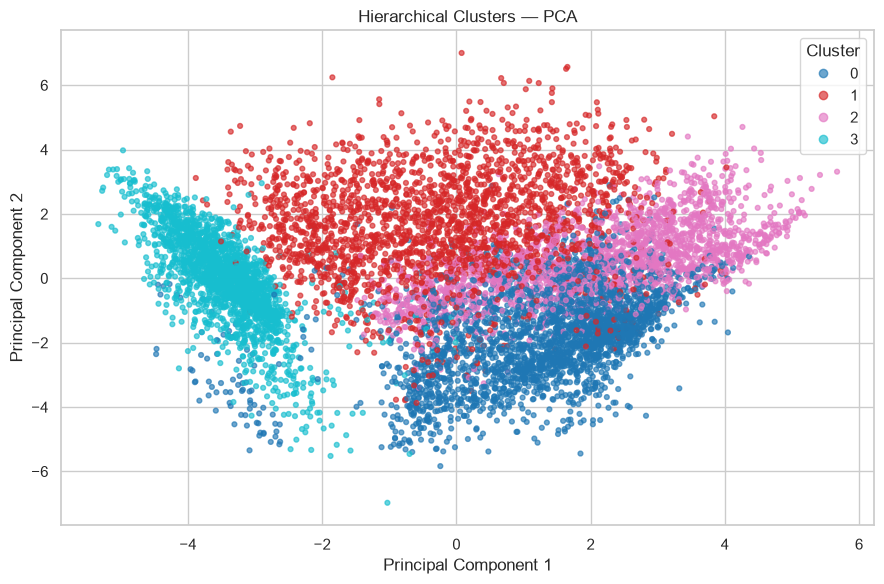

In [18]:
plot_clusters_2d(
    X_pca,
    hierarchical_labels,
    "Hierarchical Clusters — PCA"
)

#### Step 19 — Visualise the K-Means clusters with t-SNE

**What this cell does:** Takes a random sample of 2,000 customers, runs t-SNE (perplexity 30, PCA initialisation) to get a 2D map and colours it with the K-Means labels.

**Why it matters:** t-SNE keeps points that are close in the original space close together, so it often shows cluster structure that PCA hides. It is slow, so a sample is used.

**What you will see:** One scatter plot titled 'K-Means Customer Clusters — t-SNE'. This cell can take a minute to run.

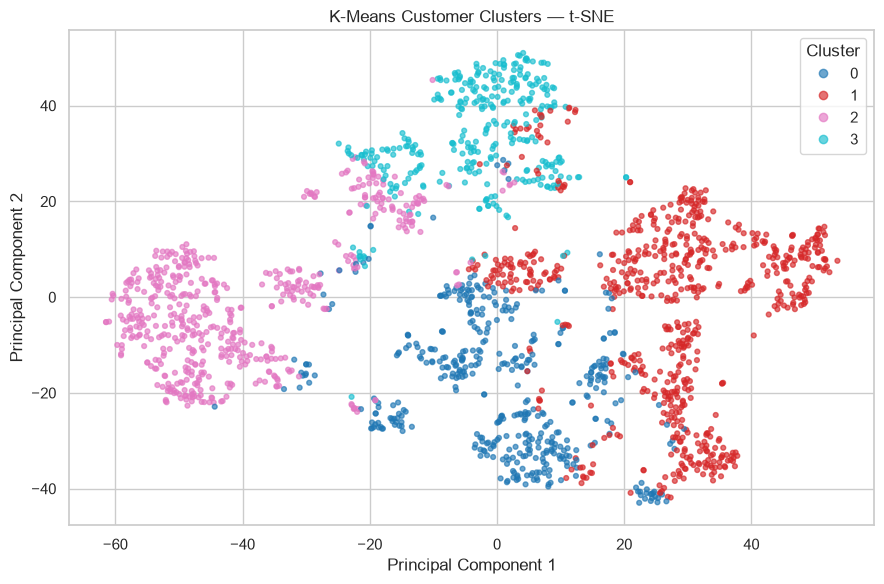

In [19]:
tsne_sample_size = min(2000, len(X_scaled))

tsne_indices = rng.choice(
    len(X_scaled),
    size=tsne_sample_size,
    replace=False
)

X_tsne_input = X_scaled.iloc[tsne_indices]
tsne_labels = kmeans_labels[tsne_indices]

tsne = TSNE(
    n_components=2,
    perplexity=min(30, tsne_sample_size - 1),
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_tsne_input)

plot_clusters_2d(
    X_tsne,
    tsne_labels,
    "K-Means Customer Clusters — t-SNE"
)

## Final Overview — Clustering Track

Clustering is unsupervised: no target label is used to fit the models. K-Means groups observations around centroids, while Agglomerative clustering merges observations or groups according to linkage distance. The Elbow curve and dendrogram help explore cluster count; neither automatically proves a single correct answer.

Compare Silhouette (higher is generally better), Davies–Bouldin (lower is generally better) and Calinski–Harabasz (higher is generally better) together. PCA and t-SNE are projections for visual inspection and can distort some relationships. Customer segment descriptions should be based on the original feature profiles, not only the plots.

#### Step 20 — Final run-specific summary

**What this cell does:** Shows the metrics table again and prints which algorithm wins on each of the three metrics (highest Silhouette, lowest Davies-Bouldin, highest Calinski-Harabasz).

**Why it matters:** Gives one place to read the final comparison. The three metrics can disagree, so use them together with the cluster sizes and the PCA/t-SNE plots before choosing a model.

**What you will see:** The metrics table followed by three 'best algorithm' lines and a reminder.

In [20]:
# Final run-specific summary, calculated from the metrics already produced above.
display(results.round(4))
best_silhouette = results.loc[results['Silhouette Score'].idxmax()]
best_db = results.loc[results['Davies-Bouldin Index'].idxmin()]
best_ch = results.loc[results['Calinski-Harabasz Index'].idxmax()]
print(f"Highest Silhouette Score: {best_silhouette['Algorithm']} ({best_silhouette['Silhouette Score']:.4f})")
print(f"Lowest Davies-Bouldin Index: {best_db['Algorithm']} ({best_db['Davies-Bouldin Index']:.4f})")
print(f"Highest Calinski-Harabasz Index: {best_ch['Algorithm']} ({best_ch['Calinski-Harabasz Index']:.2f})")
print('These metrics may disagree; choose and justify a model using all metrics, cluster sizes and feature profiles.')

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,4,0.2150,1.6559,2302.5672
1,Agglomerative Hierarchical,4,0.1784,1.8456,1916.3725


Highest Silhouette Score: K-Means (0.2150)
Lowest Davies-Bouldin Index: K-Means (1.6559)
Highest Calinski-Harabasz Index: K-Means (2302.57)
These metrics may disagree; choose and justify a model using all metrics, cluster sizes and feature profiles.
